# DBSCAN vs. K-Means

By Katie Sylvia & Jeff Hale
 
 In **Unsupervised Learning** we have different type of algorithms such as:
 
1. Clustering
2. Association Rules
3. Recommendation Engine
4. PCA
5. Text mining
6. NLP


In **Clustering** we have talked about :
1. K-Means Clustering
2. DBSCAN Clustering

In this repository we will discuss mainly about *DBSCAN Clustering*

There are some disadvantages in K-Means Clustering, among them are that they doesnt perform well with non-spherical shapes of clusters and sensitive to noise or outliers. 
   
   To deal with this we have *Density Based Spatial Clustering (DBSCAN)* :
   
     -It is mainly used to find outliers and merge them and to deal with non-spherical data
     -Clustering is mainly done based on density of data points (where more number of data points are present).


## Gapminder Data

Dataset from Gapminder World website. It provides data about the population, life expectancy and GDP in different countries of the world from 1952 to 2007. I have previously filtered the dataset to 2007. What kinds of clusters will we come up with?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:,.3f}'.format
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN, KMeans

# I. Get Data Ready

In [2]:
df = pd.read_csv('../data/2007-gapminder.csv', index_col = 'country')

In [3]:
# Head
df.head()

,continent,lifeExp,pop,gdpPercap
country,,,,
Afghanistan,Asia,43.828,31889923,974.580
Albania,Europe,76.423,3600523,"5,937.030"
Algeria,Africa,72.301,33333216,"6,223.367"
Angola,Africa,42.731,12420476,"4,797.231"
Argentina,Americas,75.320,40301927,"12,779.380"


In [4]:
# Shape
df.shape

(142, 4)

In [5]:
# Info
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 142 entries, Afghanistan to Zimbabwe
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   continent  142 non-null    object 
 1   lifeExp    142 non-null    float64
 2   pop        142 non-null    int64  
 3   gdpPercap  142 non-null    float64
dtypes: float64(2), int64(1), object(1)
memory usage: 5.5+ KB


In [6]:
# Nulls
df.isna().sum()

continent    0
lifeExp      0
pop          0
gdpPercap    0
dtype: int64

In [7]:
# Decribe
df.describe(include = 'all')

,continent,lifeExp,pop,gdpPercap
count,142,142.000,142.000,142.000
unique,5,NaN,NaN,NaN
top,Africa,NaN,NaN,NaN
freq,52,NaN,NaN,NaN
mean,NaN,67.007,"44,021,219.570","11,680.072"
std,NaN,12.073,"147,621,397.904","12,859.937"
min,NaN,39.613,"199,579.000",277.552
25%,NaN,57.160,"4,508,033.500","1,624.842"
50%,NaN,71.935,"10,517,531.000","6,124.371"
75%,NaN,76.413,"31,210,041.750","18,008.836"


In [8]:
# How many countries in each continent?

df['continent'].value_counts()

continent
Africa      52
Asia        33
Europe      30
Americas    25
Oceania      2
Name: count, dtype: int64

In [9]:
# Don't want onehotencoded vars to dominate clustering

df = df.drop(columns = 'continent')

In [10]:
# Head (again!)

df.head()

,lifeExp,pop,gdpPercap
country,,,
Afghanistan,43.828,31889923,974.580
Albania,76.423,3600523,"5,937.030"
Algeria,72.301,33333216,"6,223.367"
Angola,42.731,12420476,"4,797.231"
Argentina,75.320,40301927,"12,779.380"


In [11]:
# Define X

X = df[['lifeExp', 'pop', 'gdpPercap']]

In [12]:
# Scale Features

sc = StandardScaler()
X_scaled = sc.fit_transform(X)

# II. K-Means Clustering Model

Fit one

In [15]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10) #setting n_init to default to avoid futurewarning.
kmeans.fit(X_scaled)

KMeans(n_clusters=3, n_init=10, random_state=42)

Fit many

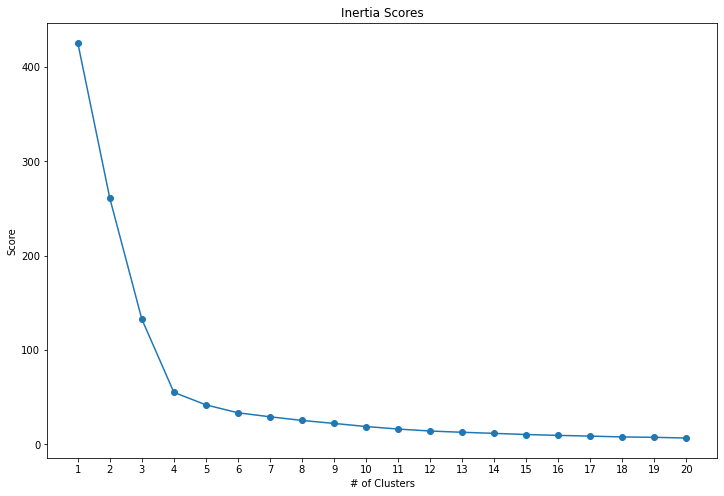

In [19]:
# Elbow Plot

inertia_list = []

for k in range(1, 21):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)

plt.figure(figsize=(12,8))
plt.plot(range(1, 21), inertia_list, marker='o')
plt.xticks(range(1, 21))
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Inertia Scores');

What is inertia?

Do I want it to be low or high?

<img src ="../imgs/low_inertia_high_sil.png" width=720>

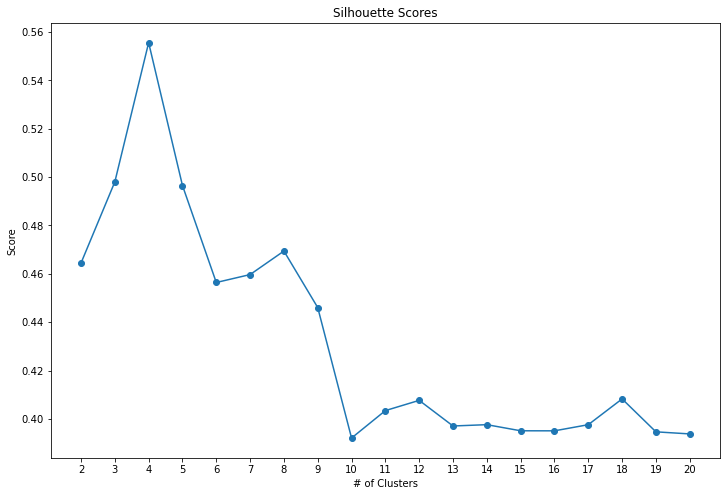

In [75]:
# Silhouette Score

silhouette_list = []

for k in range(2, 21):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))

plt.figure(figsize=(12,8))
plt.plot(range(2, 21), silhouette_list, marker='o')
plt.xticks(range(2, 21))
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Silhouette Scores');

What is silhouette score?

Do I want it to be low or high?

<img src ="../imgs/high_inertia_low_sil.png" width=720>

### Based off of our metrics above, which k should we try first?

Answer Here:
 4!


In [77]:
# Now let's try it!

# Instatiate & Fit
km = KMeans(n_clusters = 4, random_state = 42, n_init=10)
km.fit(X_scaled)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [78]:
# Silhouette Score
silhouette_score(X_scaled, km.labels_)

0.5555371637119556

### Visualize Your Clusters!

In [79]:
# Add cluster column

df['cluster'] = km.labels_

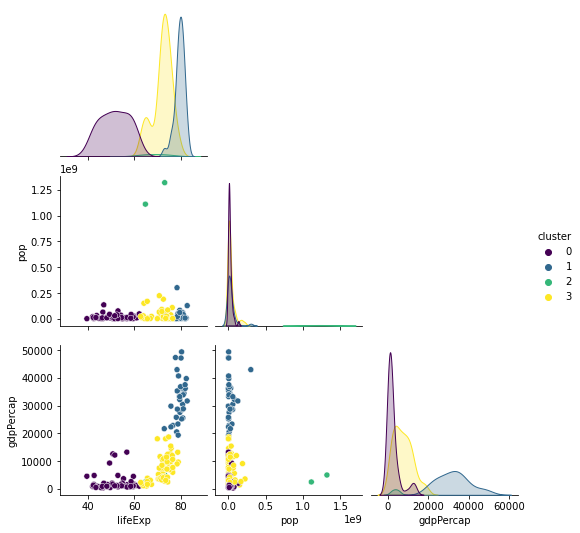

In [80]:
# Method 1: Pairplots/Scatterplots

sns.pairplot(data=df, 
             hue='cluster', 
             corner = True, 
             palette = 'viridis', 
             x_vars = ['lifeExp', 'pop', 'gdpPercap'],
             y_vars = ['lifeExp', 'pop', 'gdpPercap']);       

In [81]:
# Method 2: Groupby

df.groupby('cluster').mean().T

cluster,0,1,2,3
lifeExp,51.438,79.304,68.829,71.915
pop,"19,068,713.609","30,077,289.176","1,214,539,713.500","32,035,751.567"
gdpPercap,"2,400.702","32,293.373","3,705.663","7,379.198"


### An Even Closer Look... Which countries are in each of these clusters?

In [109]:
for i in set(km.labels_):
    print(f'Here is the list of countries in cluster {i}:')
    print('')
    print(list(df[df['cluster'] == i].index))
    print('')
    print('---')
    print('')

Here is the list of countries in cluster 0:

['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Bangladesh', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Czech Republic', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Ethiopia', 'Gabon', 'Gambia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti', 'Honduras', 'Hungary', 'Iran', 'Iraq', 'Israel', 'Jamaica', 'Jordan', 'Kenya', 'Korea, Dem. Rep.', 'Korea, Rep.', 'Lebanon', 'Lesotho', 'Liberia', 'Libya', 'Madagascar', 'Malawi', 'Malaysia', 'Mali', 'Mauritania', 'Mauritius', 'Mexico', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia', 'Nepal', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'Oman', 'Pakistan', 'Panama', '

# III. DBSCAN Clustering Model

In [83]:
# Instantiate & Fit (w/ default parameters)

dbscan = DBSCAN()
dbscan.fit(X_scaled)

DBSCAN()

In [84]:
# Silhouette Score

silhouette_score(X_scaled, dbscan.labels_)

0.39499254795173794

### Is this better or worse silhouette score than our K-Means model?

Answer Here: Worse

### Try tuning your parameters!

In [85]:
dbscan = DBSCAN(eps=5, min_samples = 3)
dbscan.fit(X_scaled)

DBSCAN(eps=5, min_samples=3)

In [86]:
silhouette_score(X_scaled, dbscan.labels_)

0.7858459160375665

### Tuning our parameters can be such a pain!

### ⭐ Can we create a function that will go through some possibilities for us? ⭐

In [87]:
# Function created by Jeff Hale

def find_best_silhouette(X):     
    ss = StandardScaler()
    X_scaled = ss.fit_transform(X)
    max_score=-1
    for eps in np.linspace(0.2, 5, 50):
        for minsamples in range(2, round(len(X) / 2)):
            dbscan = DBSCAN(eps=eps, min_samples=minsamples)
            dbscan.fit(X_scaled)
            if len(set(dbscan.labels_)) > 1:
                score = silhouette_score(X_scaled, dbscan.labels_)
                if -1 in set(dbscan.labels_):
                    nclusters = len(set(dbscan.labels_)) - 1
                else:
                    nclusters = len(set(dbscan.labels_)) 
                if score > max_score:
                    max_score = score
                    best_eps = eps
                    best_minsamples = minsamples
                    best_clusters = nclusters
    print(f'Best silhouette score was {round(max_score, 5)}')
    print(f'Best eps was {round(best_eps, 2)}')
    print(f'Best min_samples was {best_minsamples}.')
    print(f'Model found {best_clusters} clusters.')
    return

In [88]:
find_best_silhouette(X)

Best silhouette score was 0.78585
Best eps was 1.57
Best min_samples was 2.
Model found 1 clusters.


### Hm... let's talk about this.

In [89]:
# Well, let's see what the outliers are

# Instatiate & Fit
dbscan = DBSCAN(eps = 1.57, min_samples = 2)
dbscan.fit(X_scaled)

DBSCAN(eps=1.57, min_samples=2)

In [90]:
# Value Counts?
pd.Series(dbscan.labels_).value_counts()

 0    140
-1      2
Name: count, dtype: int64

### Visualize Your Clusters!

In [91]:
# Rewrite cluster label

df['cluster'] = dbscan.labels_

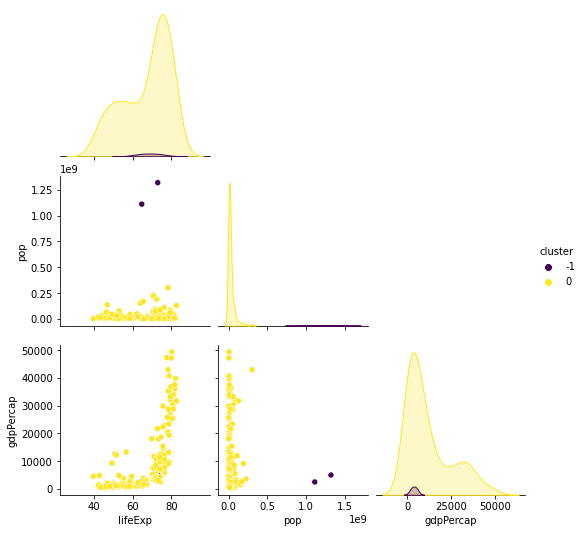

In [92]:
# Method 1: Pairplots/Scatterplots

sns.pairplot(data=df, 
             hue='cluster', 
             corner = True, 
             palette = 'viridis',
             x_vars = ['lifeExp', 'pop', 'gdpPercap'],
             y_vars = ['lifeExp', 'pop', 'gdpPercap']);       

In [93]:
# Method 2: Groupby

df.groupby('cluster').mean().T

cluster,-1,0
lifeExp,68.829,66.981
pop,"1,214,539,713.500","27,299,526.800"
gdpPercap,"3,705.663","11,793.992"


In [94]:
# Which countries were the outliers?

for i in set(dbscan.labels_):
    print(f'Here is the list of countries in cluster {i}:')
    print('')
    print(list(df[df['cluster'] == i].index))
    print('')
    print('---')
    print('')

Here is the list of countries in cluster 0:

['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bahrain', 'Bangladesh', 'Belgium', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Czech Republic', 'Denmark', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Ethiopia', 'Finland', 'France', 'Gabon', 'Gambia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti', 'Honduras', 'Hong Kong, China', 'Hungary', 'Iceland', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kenya', 'Korea, Dem. Rep.', 'Korea, Rep.', 'Kuwait', 'Lebanon', 'Lesotho', 'Liberia', 'Libya', 'Madagascar', 'Malawi', 'Malaysia', 'Mal

## ⭐ Can we change our function to make sure we have some clusters? ⭐

In [95]:
# Function created by Jeff Hale

def find_best_silhouette(X): 
    ss = StandardScaler()
    X_scaled = ss.fit_transform(X)
    max_score=-1     
    for eps in np.linspace(0.25, 5, 20):
        for minsamples in range(2, round(len(X) / 2)):
            dbscan = DBSCAN(eps=eps, min_samples=minsamples)
            dbscan.fit(X_scaled)
            if len(set(dbscan.labels_)) >= 3: # CHANGE IT HERE!
                score = silhouette_score(X_scaled, dbscan.labels_)
                if -1 in set(dbscan.labels_):
                    nclusters = len(set(dbscan.labels_)) - 1
                else:
                    nclusters = len(set(dbscan.labels_)) 
                if score > max_score:
                    max_score = score
                    best_eps = eps
                    best_minsamples = minsamples
                    best_clusters = nclusters
    print(f'Best silhouette score was {round(max_score, 2)}')
    print(f'Best eps was {round(best_eps, 2)}')
    print(f'Best min_samples was {best_minsamples}.')
    print(f'Model found {best_clusters} clusters.')
    return

In [96]:
find_best_silhouette(X)

Best silhouette score was 0.42
Best eps was 0.75
Best min_samples was 24.
Model found 2 clusters.


In [97]:
# Now fit a model with new parameters

dbscan=DBSCAN(eps=0.75, min_samples = 24)
dbscan.fit(X_scaled)

DBSCAN(eps=0.75, min_samples=24)

In [98]:
# Value Counts?

pd.Series(dbscan.labels_).value_counts()

 0    113
 1     21
-1      8
Name: count, dtype: int64

In [99]:
# Rewrite cluster label

df['cluster'] = dbscan.labels_

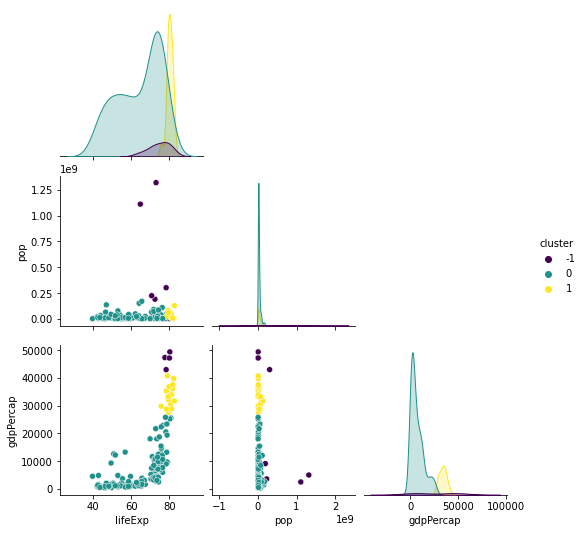

In [100]:
# Method 1: Pairplots/Scatterplots

sns.pairplot(data=df, 
             hue='cluster', 
             corner = True, 
             palette = 'viridis',
             x_vars = ['lifeExp', 'pop', 'gdpPercap'],
             y_vars = ['lifeExp', 'pop', 'gdpPercap']);       

In [101]:
# Method 2: Groupby

df.groupby('cluster').mean().T

cluster,-1,0,1
lifeExp,74.587,64.047,80.052
pop,"394,432,939.375","22,150,130.655","28,218,328.571"
gdpPercap,"25,847.099","6,611.019","33,559.443"


In [102]:
# Which countries were the outliers?

for i in set(dbscan.labels_):
    print(f'Here is the list of countries in cluster {i}:')
    print('')
    print(list(df[df['cluster'] == i].index))
    print('')
    print('---')
    print('')

Here is the list of countries in cluster 0:

['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Bangladesh', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Czech Republic', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Ethiopia', 'Gabon', 'Gambia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti', 'Honduras', 'Hungary', 'Iran', 'Iraq', 'Israel', 'Jamaica', 'Jordan', 'Kenya', 'Korea, Dem. Rep.', 'Korea, Rep.', 'Lebanon', 'Lesotho', 'Liberia', 'Libya', 'Madagascar', 'Malawi', 'Malaysia', 'Mali', 'Mauritania', 'Mauritius', 'Mexico', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia', 'Nepal', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'Oman', 'Pakistan', 'Panama', '

## ⭐ There are many pros & cons for DBSCAN and K-Means Clustering Models. Again, since this is unsupervised it is hard to know which method you should use! Keep exploring and diving into your data 💫 